# Chapter 0: Exploring the data

What does the competition data look like, and what does that mean for how we evaluate?
All logic lives in the `forgery` package; this notebook only calls it and plots.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from forgery.data import EXCLUDED_SUPPLEMENTAL_IDS, build_index, load_image, load_masks
from forgery.split import get_slice, load_split

index = build_index()
print(f"{len(index)} image files")

5176 image files


## 1. How many images of each kind?

Three sources: authentic training images, forged training images (each with a mask file),
and a small supplemental set of forged images. Every image also belongs to a slice:
train or val (our split), or supplemental (a separate small evaluation set).

In [2]:
slice_of = {}
for name in ("train", "val", "supplemental"):
    slice_of.update(dict.fromkeys(get_slice(name, index).sample_id, name))
index["slice"] = index.sample_id.map(slice_of)
pd.crosstab(index.source, index.slice, margins=True)

slice,supplemental,train,val,All
source,,,,
authentic,0,1902,475,2377
forged,0,2201,550,2751
supplemental,48,0,0,48
All,48,4103,1025,5176


## 2. Image sizes, forged area, and number of forged regions

A mask has one layer ("instance") per forged region. The forged area fraction is the share
of the image covered by the union of all layers.

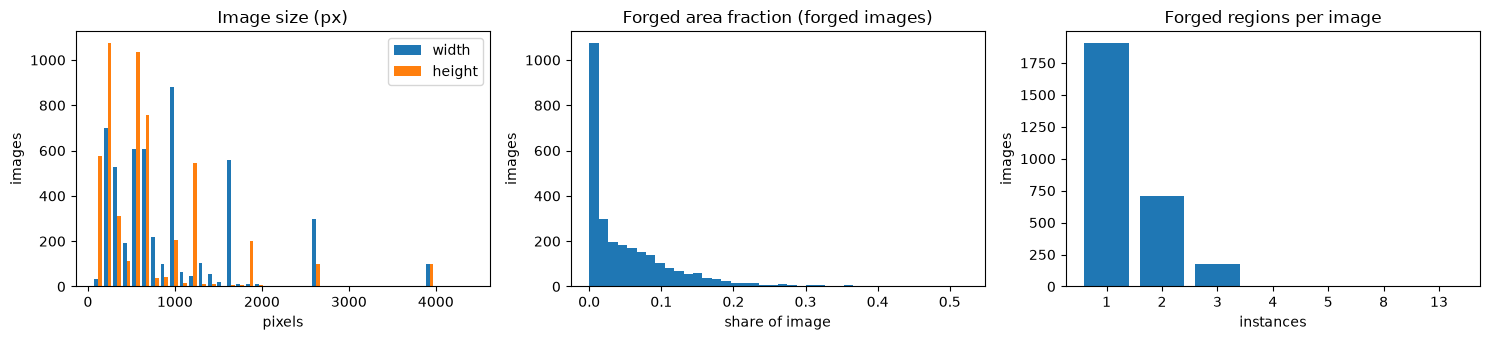

count    2799.0000
mean        0.0560
std         0.0700
min         0.0004
10%         0.0037
50%         0.0282
90%         0.1440
max         0.5227
Name: area_fraction, dtype: float64
n_instances
1     1902
2      710
3      176
4        7
5        2
8        1
13       1


In [3]:
forged = index[index.source != "authentic"].copy()
forged["area_fraction"] = [
    np.maximum.reduce(load_masks(p)).mean() for p in forged.mask_path
]

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
ax[0].hist([index.width, index.height], bins=40, label=["width", "height"])
ax[0].set(title="Image size (px)", xlabel="pixels", ylabel="images")
ax[0].legend()
ax[1].hist(forged.area_fraction, bins=40)
ax[1].set(title="Forged area fraction (forged images)", xlabel="share of image", ylabel="images")
counts = forged.n_instances.value_counts().sort_index()
ax[2].bar(counts.index.astype(str), counts.values)
ax[2].set(title="Forged regions per image", xlabel="instances", ylabel="images")
plt.tight_layout()
plt.show()

print(forged.area_fraction.describe(percentiles=[0.1, 0.5, 0.9]).round(4))
print(counts.to_string())

## 3. Twins: an authentic image and its forged copy

Every authentic image has a forged twin with the same case ID. The difference image shows
which pixels the forger changed; the mask marks the duplicated regions. Twins differ in only
a tiny fraction of pixels, which is why the split must keep each pair on the same side:
otherwise validation would mostly test whether a model memorised the original.

Look closely: the changed pixels show only the **pasted copy**, but the mask marks **both the
copy and the source region it was copied from** (case 33064: one changed blob, two masked
blobs). The source is untouched, so it carries no trace of editing. It can only be found by
noticing that it matches the copy, which is the core idea behind duplicate search.

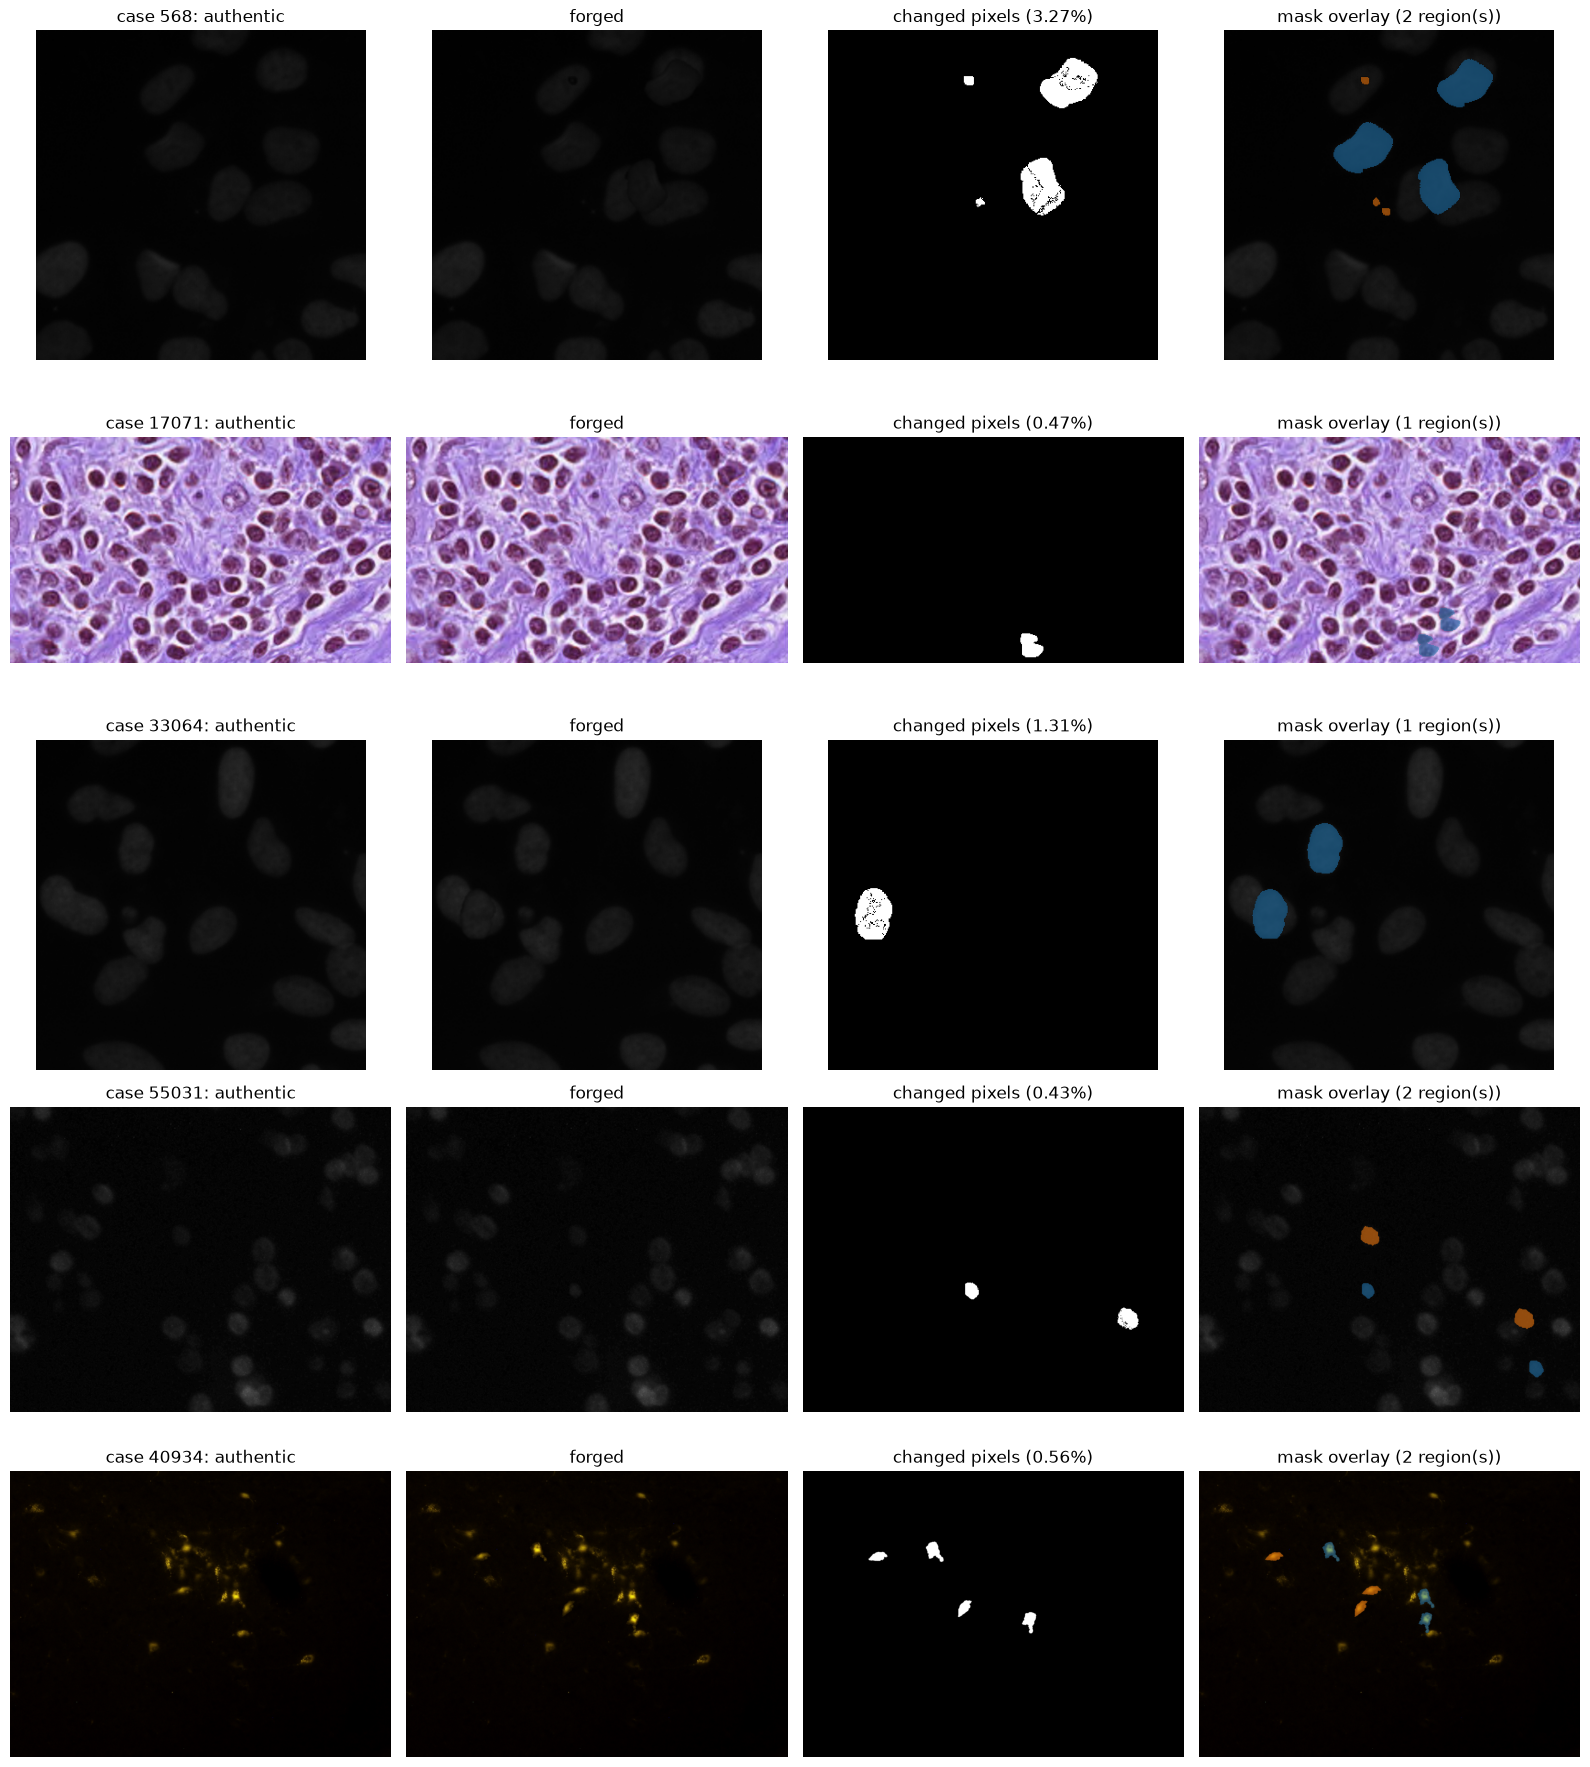

In [4]:
twin_ids = sorted(set(index[index.source == "authentic"].case_id))
rng = np.random.default_rng(0)
examples = [568] + [int(c) for c in rng.choice([c for c in twin_ids if c != 568], 4, replace=False)]
by_key = index.set_index(["source", "case_id"])

fig, ax = plt.subplots(len(examples), 4, figsize=(16, 3.6 * len(examples)))
for r, case_id in enumerate(examples):
    authentic = load_image(by_key.loc[("authentic", case_id), "image_path"])
    forged_img = load_image(by_key.loc[("forged", case_id), "image_path"])
    masks = load_masks(by_key.loc[("forged", case_id), "mask_path"])
    diff = np.abs(authentic.astype(int) - forged_img.astype(int)).sum(-1)
    overlay = forged_img.astype(float)
    for i, mask in enumerate(masks):
        color = np.array(plt.cm.tab10(i)[:3]) * 255
        overlay[mask == 1] = 0.45 * overlay[mask == 1] + 0.55 * color
    panels = [
        (authentic, f"case {case_id}: authentic"),
        (forged_img, "forged"),
        (diff > 0, f"changed pixels ({(diff > 0).mean():.2%})"),
        (overlay.astype(np.uint8), f"mask overlay ({len(masks)} region(s))"),
    ]
    for c, (img, title) in enumerate(panels):
        ax[r, c].imshow(img, cmap="gray" if img.ndim == 2 else None)
        ax[r, c].set_title(title)
        ax[r, c].axis("off")
plt.tight_layout()
plt.show()

## 4. Supplemental IDs that also appear in training

Four supplemental case IDs also exist among the forged training images. If they were the
same picture, they would be scored twice; `EXCLUDED_SUPPLEMENTAL_IDS` would list them.

case 20833: identical=False -> kept
case 24032: identical=False -> kept
case 31168: identical=False -> kept
case 32575: identical=False -> kept


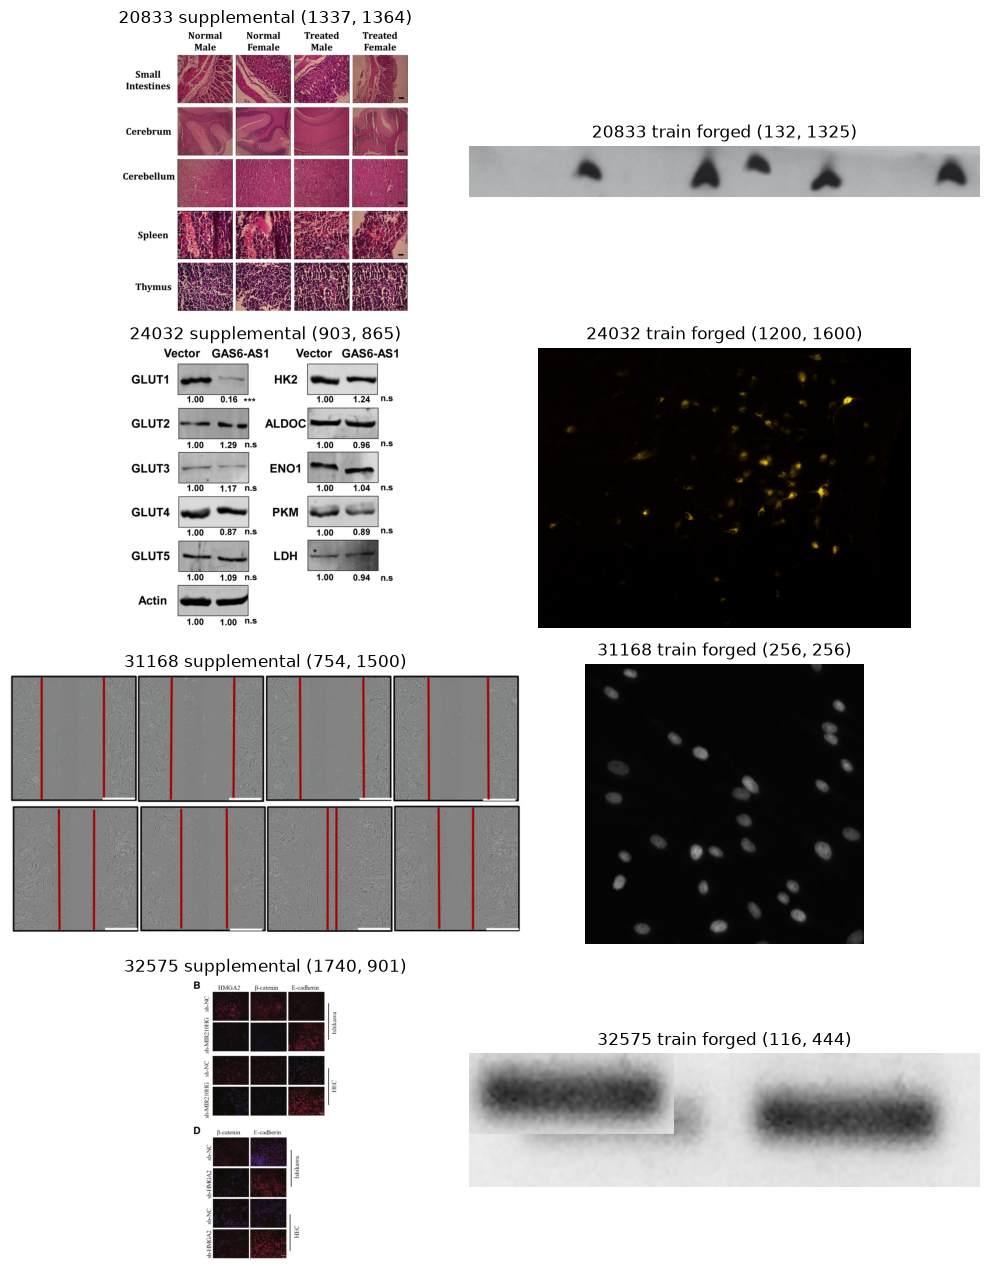

In [5]:
overlap = sorted(set(index[index.source == "supplemental"].case_id) & set(index[index.source == "forged"].case_id))
fig, ax = plt.subplots(len(overlap), 2, figsize=(10, 3.2 * len(overlap)))
for r, case_id in enumerate(overlap):
    supp = load_image(by_key.loc[("supplemental", case_id), "image_path"])
    train = load_image(by_key.loc[("forged", case_id), "image_path"])
    same = supp.shape == train.shape and np.array_equal(supp, train)
    verdict = "excluded" if case_id in EXCLUDED_SUPPLEMENTAL_IDS else "kept"
    for c, (img, label) in enumerate([(supp, "supplemental"), (train, "train forged")]):
        ax[r, c].imshow(img)
        ax[r, c].set_title(f"{case_id} {label} {img.shape[:2]}")
        ax[r, c].axis("off")
    print(f"case {case_id}: identical={same} -> {verdict}")
plt.tight_layout()
plt.show()

## 5. The validation split

20% of training cases, chosen separately among twin pairs and forged-only cases (stratified)
with a fixed seed, and stored in `splits/val_case_ids.txt`.

In [6]:
val_cases = load_split()
twins = set(twin_ids)
val_rows = index[index.slice == "val"]
print(f"val cases: {len(val_cases)} ({len(val_cases & twins)} twin pairs, {len(val_cases - twins)} forged-only)")
print(f"val images: {len(val_rows)}")
print(val_rows.source.value_counts().to_string())
print(f"authentic share of val images: {(val_rows.source == 'authentic').mean():.3f}")

val cases: 550 (475 twin pairs, 75 forged-only)
val images: 1025
source
forged       550
authentic    475
authentic share of val images: 0.463


## 6. How the metric scores a prediction (image 568)

Image 568 has two true regions. Below, five hand-made predictions are scored with the real
metric code. Note how a missed small region, an extra mask, or merging two regions each cost
far more than a slightly-too-big mask.

In [7]:
from scipy.ndimage import binary_dilation

from forgery.metric import score_image

gt = load_masks(by_key.loc[("forged", 568), "mask_path"])
big, small = gt
junk = np.zeros_like(big)
junk[:20, :20] = 1
cases = {
    "both regions exactly right": [big, small],
    "big region drawn too large, small region right": [binary_dilation(big, iterations=6).astype(np.uint8), small],
    "both right, plus one extra junk mask": [big, small, junk],
    "only the big region (small one missed)": [big],
    "both regions merged into one mask": [np.maximum(big, small)],
}
print(f"true region sizes: {int(big.sum())} and {int(small.sum())} pixels")
for name, pred in cases.items():
    print(f"{score_image(pred, gt):.3f}  {name}")

true region sizes: 6243 and 185 pixels
1.000  both regions exactly right
0.905  big region drawn too large, small region right
0.667  both right, plus one extra junk mask
0.500  only the big region (small one missed)
0.493  both regions merged into one mask


## 7. Validation vs supplemental forgeries

The two evaluation sets differ: this explains why a whole-image mask scores much better on
supplemental images than on validation images.

In [8]:
for name in ("val", "supplemental"):
    rows = forged[forged.slice == name]
    print(f"{name:13s} forged={len(rows):4d}  median area={rows.area_fraction.median():.3f}  "
          f"mean area={rows.area_fraction.mean():.3f}  mean regions={rows.n_instances.mean():.2f}")

val           forged= 550  median area=0.022  mean area=0.051  mean regions=1.38
supplemental  forged=  48  median area=0.067  mean area=0.102  mean regions=1.79
